# Week 8 activities: data visualization

# Setup

In [1]:
# packages
import pandas as pd
import numpy as np
import os
from plotnine import *  # may need to install plotnine via pip install or conda install
import matplotlib.pyplot as plt  
import seaborn as sns # may need to install

# print multiple objects from the same cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"


Load the datasets

- `childnoinsur_complete.csv`. Store this as `ci`
- `childpov_insur_2324.csv`. Store this as `df` - this is the merged dataset for 2023 and 2024 we created in the previous activity

All data can be found on this page: https://rebeccajohnson88.github.io/PPOL5203_fall2026/datasets.html

In [39]:
ci = pd.read_csv("../datasets/childnoinsur_complete.csv")
df = pd.read_csv("../datasets/childpov_insur_2324.csv")

In [40]:
ci.head()
df.head()

,State,Race,Year,uninsured_rate,Census_Division
0,Wyoming,Non-Hispanic White,2018,0.07,Mountain
1,Wyoming,Hispanic or Latino,2018,0.06,Mountain
2,Wyoming,Black or African American,2018,0.02,Mountain
3,Wyoming,Asian and Pacific Islander,2018,0.02,Mountain
4,Wisconsin,Two or more races,2018,0.02,East North Central


,state,year,race_ethnicity,child_poverty_rate,uninsured_rate,census_division
0,Alabama,2023,American Indian or Alaska Native,NaN,0.04,East South Central
1,Alabama,2023,Asian and Pacific Islander,0.08,NaN,East South Central
2,Alabama,2023,Black or African American,0.41,0.05,East South Central
3,Alabama,2023,Hispanic or Latino,0.27,0.10,East South Central
4,Alabama,2023,Non-Hispanic White,0.11,0.02,East South Central


# Activity 1: continuous data in child uninsurance

A. 

- Subset the child uninsurance data (`ci`) to the year 2024
- Use plotnine to create a histogram of the child uninsurance rate (not separating out by race/ethnicity group) with 20 bins


,State,Race,Year,uninsured_rate,Census_Division
749,Alaska,American Indian or Alaska Native,2024,0.10,Pacific
750,Alaska,Asian and Pacific Islander,2024,0.11,Pacific
751,Alaska,Hispanic or Latino,2024,0.07,Pacific
752,Alaska,Non-Hispanic White,2024,0.07,Pacific
753,Alaska,Two or more races,2024,0.10,Pacific


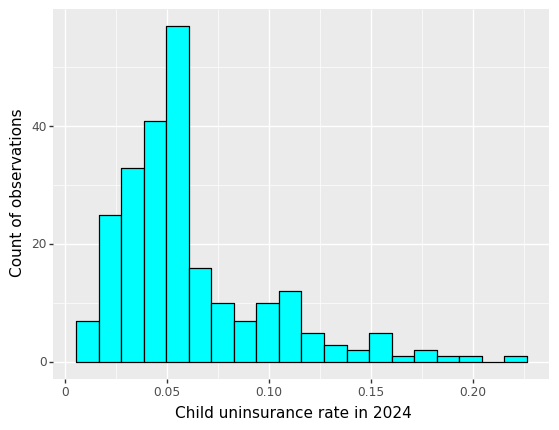

<ggplot: (8771922599295)>

In [7]:
ci_24 = ci[ci.Year == 2024].copy()
ci_24.head()
(ggplot(ci_24, aes(x = 'uninsured_rate')) +
geom_histogram(color = 'black', fill = 'cyan', bins = 20) +
xlab("Child uninsurance rate in 2024") +
ylab("Count of observations"))

B. Add a facet_wrap to the plot from part A to create a separate facet for each race/ethnicity group

What do you notice about how the distributions differ across groups?

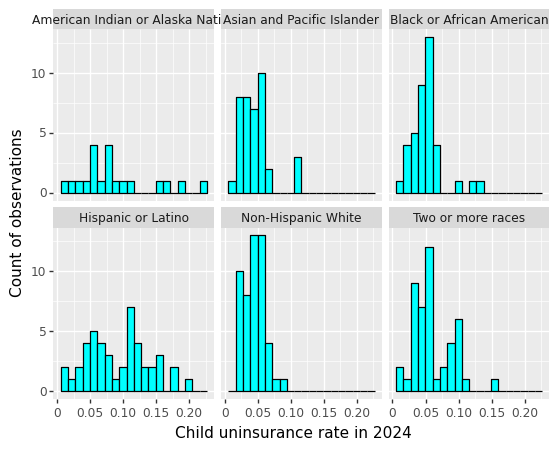

<ggplot: (8771868206005)>

In [8]:
(ggplot(ci_24, aes(x = 'uninsured_rate')) +
geom_histogram(color = 'black', fill = 'cyan', bins = 20) +
xlab("Child uninsurance rate in 2024") +
ylab("Count of observations") +
facet_wrap('~Race'))

C. Create the same plot from part B using `seaborn`; feel free to use generative AI to assist you in translating the code

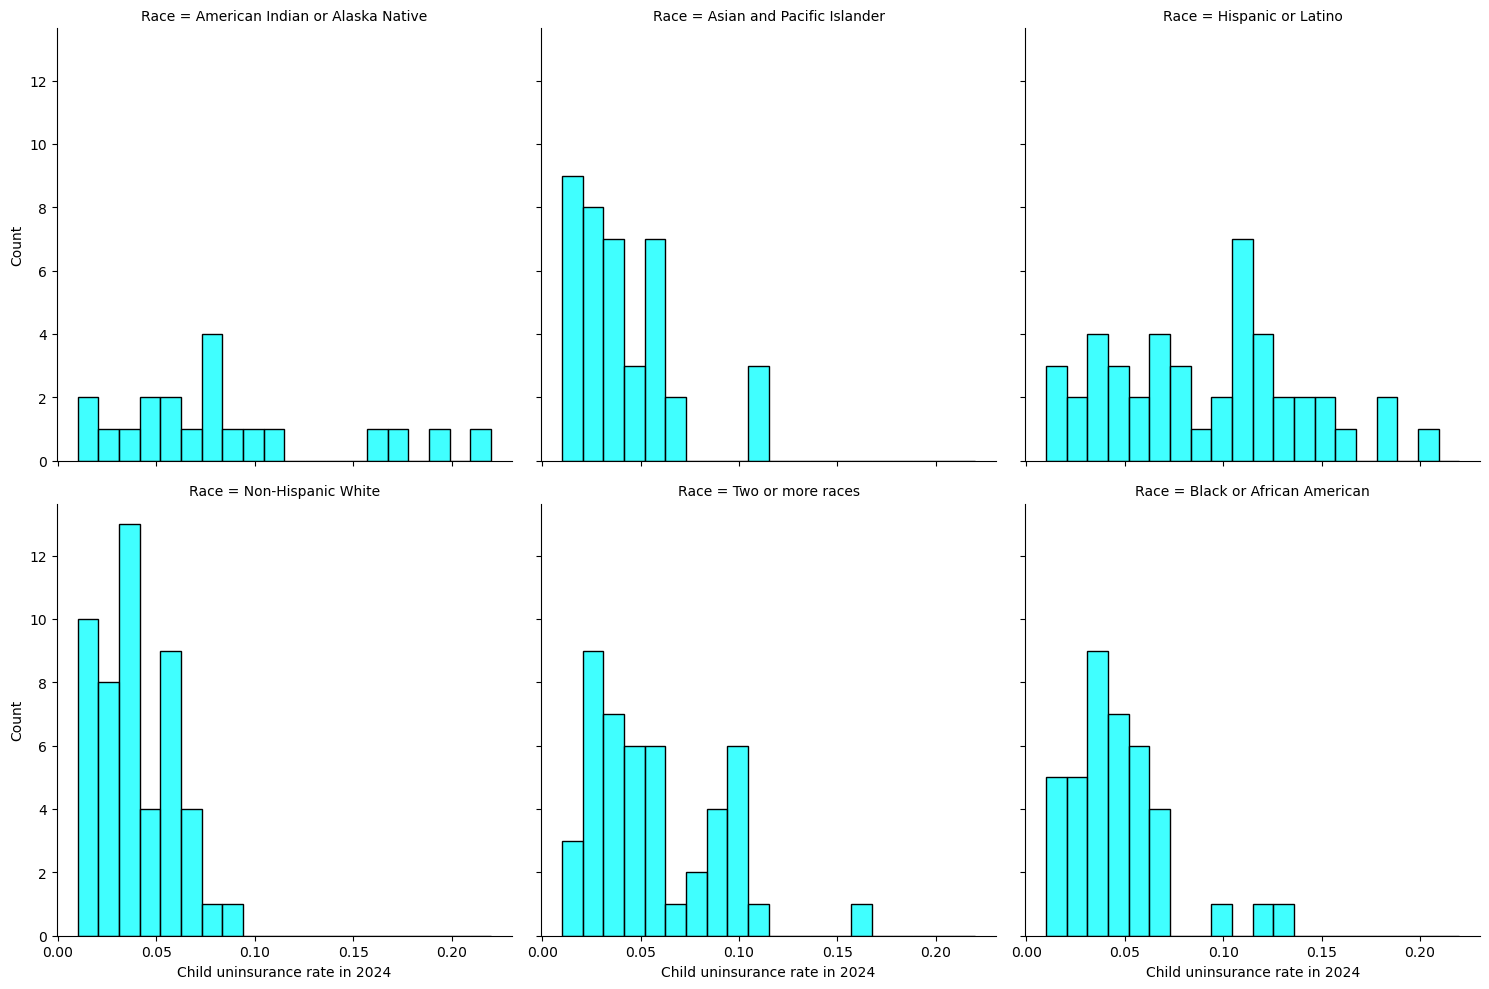

In [9]:
g  = sns.displot(data = ci_24, 
                x = 'uninsured_rate',
                col = 'Race', col_wrap = 3, 
                bins = 20, color = 'cyan', edgecolor = 'black')
g = g.set_axis_labels('Child uninsurance rate in 2024', y = 'Count of observations')
plt.show()

# Activity 2: categorical versus continuous in child uninsurance

A. 

- Use the same child uninsurance data subsetted to 2024
- Use a group by / aggregate statement to get the mean uninsurance rate for each race/ethnicity group
- Create a barplot where the x axis is the race/ethnicity group and the y axis is the mean uninsurance rate for that group across states, ordered from highest to lowest uninsurance rate

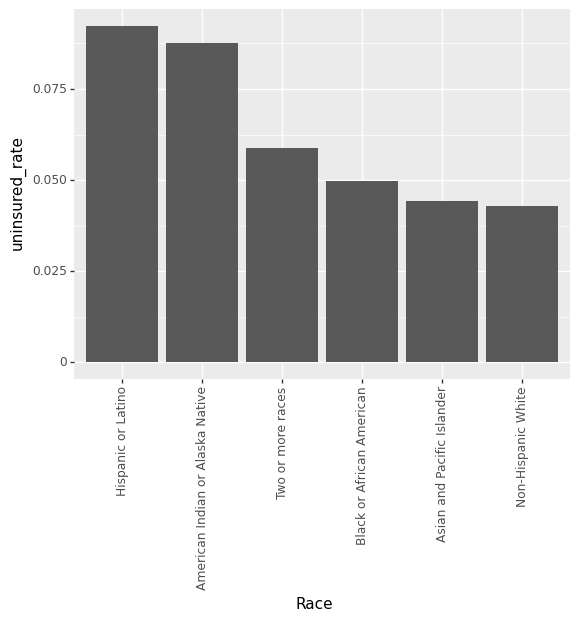

<ggplot: (8771922563771)>

In [29]:
ci_byr = ci_24.groupby('Race')['uninsured_rate'].mean().reset_index().sort_values(by = 
            'uninsured_rate', ascending = False)

(ggplot(ci_byr, aes(x = 'Race', y = 'uninsured_rate')) +
geom_bar(stat = 'identity') +
scale_x_discrete(limits = ci_byr.Race) +
theme(axis_text_x = element_text(rotation = 90)))



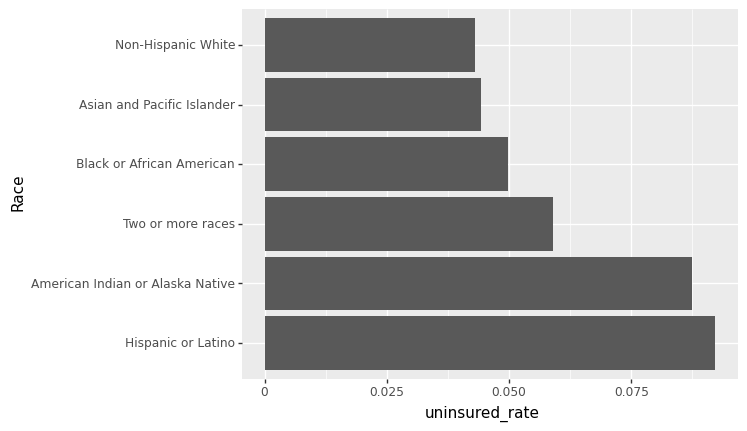

<ggplot: (8771833318464)>

In [27]:
(ggplot(ci_byr, aes(x = 'Race', y = 'uninsured_rate')) +
geom_bar(stat = 'identity') +
scale_x_discrete(limits = ci_byr.Race) +
coord_flip())

B. 

- Use the same child uninsurance data subsetted to 2024
- Use a group by / aggregate statement to get the mean uninsurance rate by race/ethnicity group WITHIN each Census Division 
- Create a barplot where the x axis is the race/ethnicity group, the y axis is the mean uninsurance rate for that group, and the plot is faceted to show each separate Census Division

In [34]:
ci_byr_byd = ci_24.groupby(['Race', 'Census_Division'])['uninsured_rate'].mean().\
                    reset_index()

ci_byr_byd.head()

ci_byr_byd = ci_byr_byd.sort_values(['Census_Division', 'uninsured_rate'],
                           ascending = False)

# Convert item to a categorical variable respecting the sorted order per group
ci_byr_byd['r_ordered'] = pd.Categorical(ci_byr_byd['Race'], 
                    categories=ci_byr_byd['Race'].unique(), ordered=True)


,Race,Census_Division,uninsured_rate
0,American Indian or Alaska Native,East North Central,0.0575
1,American Indian or Alaska Native,East South Central,0.0500
2,American Indian or Alaska Native,Middle Atlantic,0.0700
3,American Indian or Alaska Native,Mountain,0.1375
4,American Indian or Alaska Native,New England,0.0100


/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/facets/facet.py:446: PlotnineWarning: If you need more space for the y-axis tick text use ... + theme(subplots_adjust={'hspace': 0.25}). Choose an appropriate value for 'hspace'


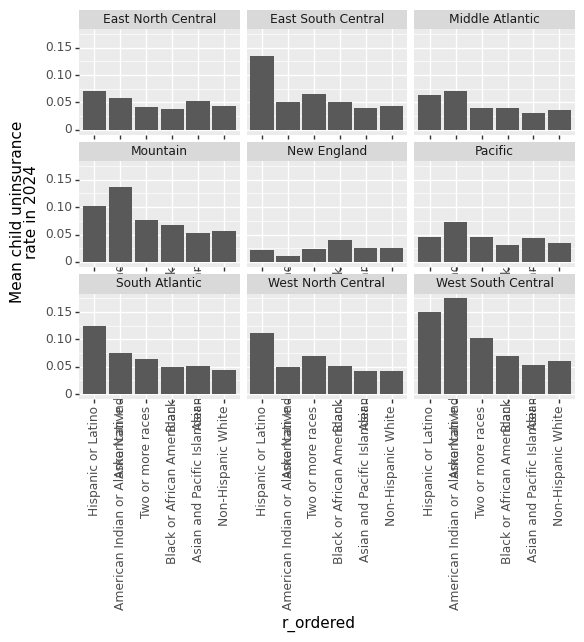

<ggplot: (8771849983223)>

In [35]:
##
(ggplot(ci_byr_byd, aes(x = 'r_ordered', y = 'uninsured_rate')) +
geom_bar(stat = 'identity') +
ylab("Mean child uninsurance\nrate in 2024") +
facet_wrap('~Census_Division', scales = 'free_x') +
scale_x_discrete(limits = ci_byr.Race) +
theme(axis_text_x = element_text(rotation = 90)))



C. 

- Return to data from the full panel of years 
- Find the mean child uninsurance rate for each racial/ethnic group and each year
- Create a lineplot where the:
    - x axis is the year 
    - y axis is the mean child uninsurance rate for that year
    - lines connect the years 
    - facet_wrap creates a separate plot for each racial/ethnic group

In [36]:
ci_year = ci.groupby(['Race', 'Year'])['uninsured_rate'].mean().\
                    reset_index()

ci_year


,Race,Year,uninsured_rate
0,American Indian or Alaska Native,2017,0.089130
1,American Indian or Alaska Native,2018,0.091667
2,American Indian or Alaska Native,2019,0.085000
3,American Indian or Alaska Native,2021,0.086190
4,American Indian or Alaska Native,2022,0.070909
5,American Indian or Alaska Native,2023,0.080435
6,American Indian or Alaska Native,2024,0.087500
7,Asian and Pacific Islander,2017,0.044048
8,Asian and Pacific Islander,2018,0.043333
9,Asian and Pacific Islander,2019,0.045278


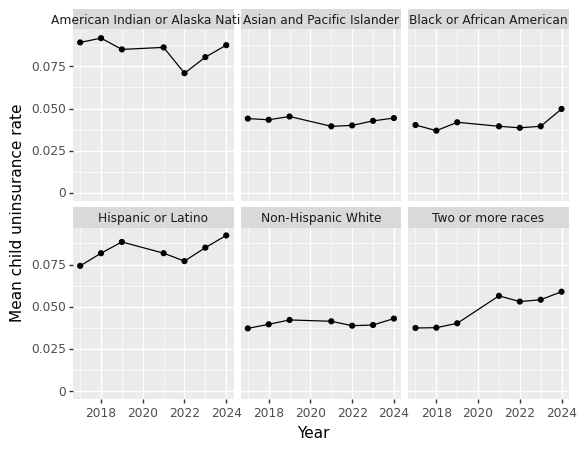

<ggplot: (8771849968725)>

In [37]:

(ggplot(ci_year, aes(x = 'Year', y = 'uninsured_rate')) +
geom_point() +
geom_line() +
ylim(0, np.max(ci_year.uninsured_rate)) +
ylab("Mean child uninsurance rate") +
facet_wrap('~Race'))

# Activity 3: continuous versus continuous 



A. 

- Using `df` (the merged dataset), create a scatterplot where the child poverty rate is on the x axis, the child uninsurance rate is on the y axis, and each dot is a particular state-year-group observation


In [41]:
df.head()

,state,year,race_ethnicity,child_poverty_rate,uninsured_rate,census_division
0,Alabama,2023,American Indian or Alaska Native,NaN,0.04,East South Central
1,Alabama,2023,Asian and Pacific Islander,0.08,NaN,East South Central
2,Alabama,2023,Black or African American,0.41,0.05,East South Central
3,Alabama,2023,Hispanic or Latino,0.27,0.10,East South Central
4,Alabama,2023,Non-Hispanic White,0.11,0.02,East South Central


/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/layer.py:411: PlotnineWarning: geom_point : Removed 311 rows containing missing values.


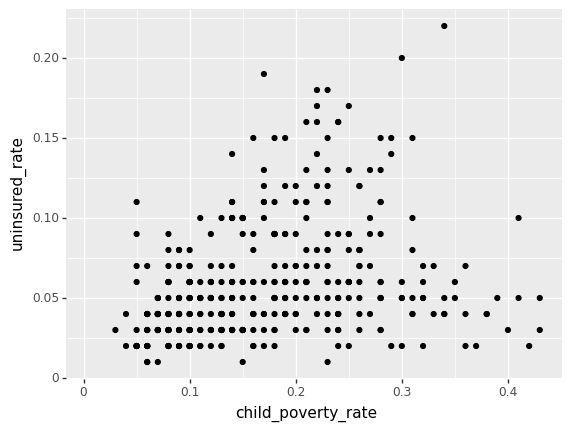

<ggplot: (8771834387441)>

In [44]:
(ggplot(df, aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
      geom_point())

B. Add a smoother to the plot

/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/layer.py:411: PlotnineWarning: geom_point : Removed 311 rows containing missing values.


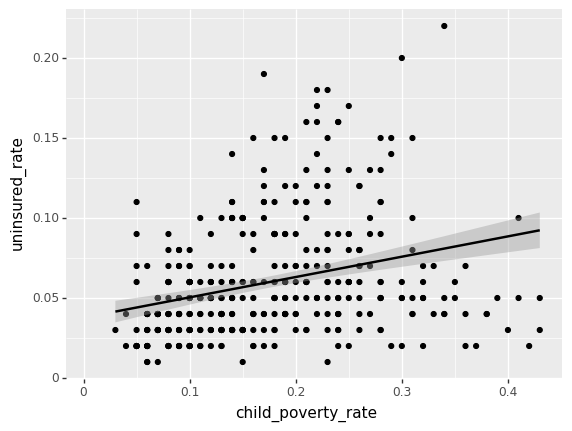

<ggplot: (8771900499047)>

In [48]:
(ggplot(df, aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
      geom_point() +
geom_smooth(method = 'lm'))

C. Facet by child race/ethnicity 

What patterns and/or data limitations do you notice?

/Users/rj545/opt/anaconda3/lib/python3.9/site-packages/plotnine/layer.py:411: PlotnineWarning: geom_point : Removed 311 rows containing missing values.


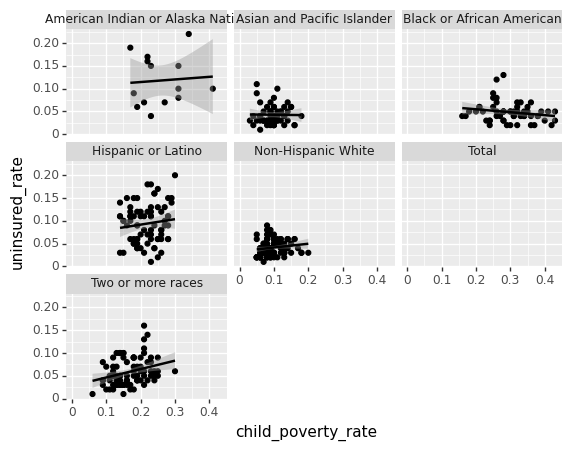

<ggplot: (8771868210348)>

In [50]:
(ggplot(df, aes(x = 'child_poverty_rate', y = 'uninsured_rate')) +
      geom_point() +
geom_smooth(method = 'lm') +
facet_wrap('~race_ethnicity'))